## January 2026 
In this file I will test the output of the new version of CosmoTherm FH. <br>
I will look at the anisotropic spectral distortions sourced by photon to dark photon conversion and compare it with a normal gaussian heating. <br>


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from pathlib import Path
import math
from scipy.interpolate import CubicSpline 

import tools
import my_plot as mplt

In [2]:
def extract_custom_state_from_files(folder_path, ell, pattern="custom_state_kv_001_yn_aniso_system-all_wG.dat_ymax15_lmax25_adiabatic.dat"):
    """Extract custom transfer function data from files in a folder """
    folder = Path(folder_path) / "batch" / "FH" 
    file_path = next(folder.glob(pattern))
    
    theta = [[] for _ in range(ell+1)]
    mu = [[] for _ in range(ell+1)]
    y = [[] for _ in range(ell+1)]
    z = []
    
    data = np.loadtxt(file_path, comments='#')  
    z.extend(data[:, 0])  # First column is redshift
    for i in range(ell+1):
        theta[i].extend(data[:, 1+i*(ell)])   # All theta values from column 1 and multiples of it
        print( " theta ", i, "comes from column ", 1+i*(ell))
        y[i].extend(data[:, 2+i*(ell)])       # All y values from column 2 and multiples of it
        print( " y ", i, "comes from column ", 2+i*(ell))
        mu[i].extend(data[:, 3+i*(ell)])  # All mu values from column 3 and multiples of it
        print( " mu ", i, "comes from column ", 3+i*(ell))
    
    return z, np.array(theta), np.array(y), np.array(mu)

In [62]:
def extract_state_scattering_basis(folder_path, ell, k, basis="scattering"):
    """Extract scattering basis transfer function data from files in a folder """
    folder = Path(folder_path) 
    file_path = []
    file_path2 = []
    # Collect multipole files (0,1,2,...)
    for i in range(ell+1):
        file_path.append(next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax50_adiabatic_scattering-basis_{i}.dat")))
        # theta values always come from the computational basis for the scattering
        file_path2.append(next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax50_adiabatic_computation-basis_{i}.dat"))) 
    # Collect background file
    bg_file = next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax50_adiabatic_scattering-basis_bg.dat"))
    bg_file2 = next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax50_adiabatic_computation-basis_bg.dat"))

    theta = [[] for _ in range(ell+2)]
    mu = [[] for _ in range(ell+2)]
    y = [[] for _ in range(ell+2)]
    a = []

    # First: background
    data_bg = np.loadtxt(bg_file, comments='#')
    data_theta_bg = np.loadtxt(bg_file2, comments='#')
    a.extend(data_bg[:, 0])  # First column is redshift (only read once)
    theta[0].extend(data_theta_bg[:, 1])
    y[0].extend(data_bg[:, 2])
    mu[0].extend(data_bg[:, 9])

    # Then: multipoles
    for i in range(ell+1):
        data = np.loadtxt(file_path[i], comments='#')
        data_theta = np.loadtxt(file_path2[i], comments='#')
        theta[i+1].extend(data_theta[:, 1])
        y[i+1].extend(data[:, 2])
        mu[i+1].extend(data[:, 9])

    return a, np.array(theta), np.array(y), np.array(mu)

In [63]:
ell = 2
kv_values = ["001", "002", "003"]
theta = []
y = []
mu = []
a = []

for kv in kv_values:
    zt, th, yy, m = extract_state_scattering_basis("../Data/dp-aniso-nah1/", ell, kv )
    
    theta.append(th)
    y.append(yy)
    mu.append(m)
    a.append(zt)

In [ ]:
kv_values_Mpc = [1,0.1,0.01]


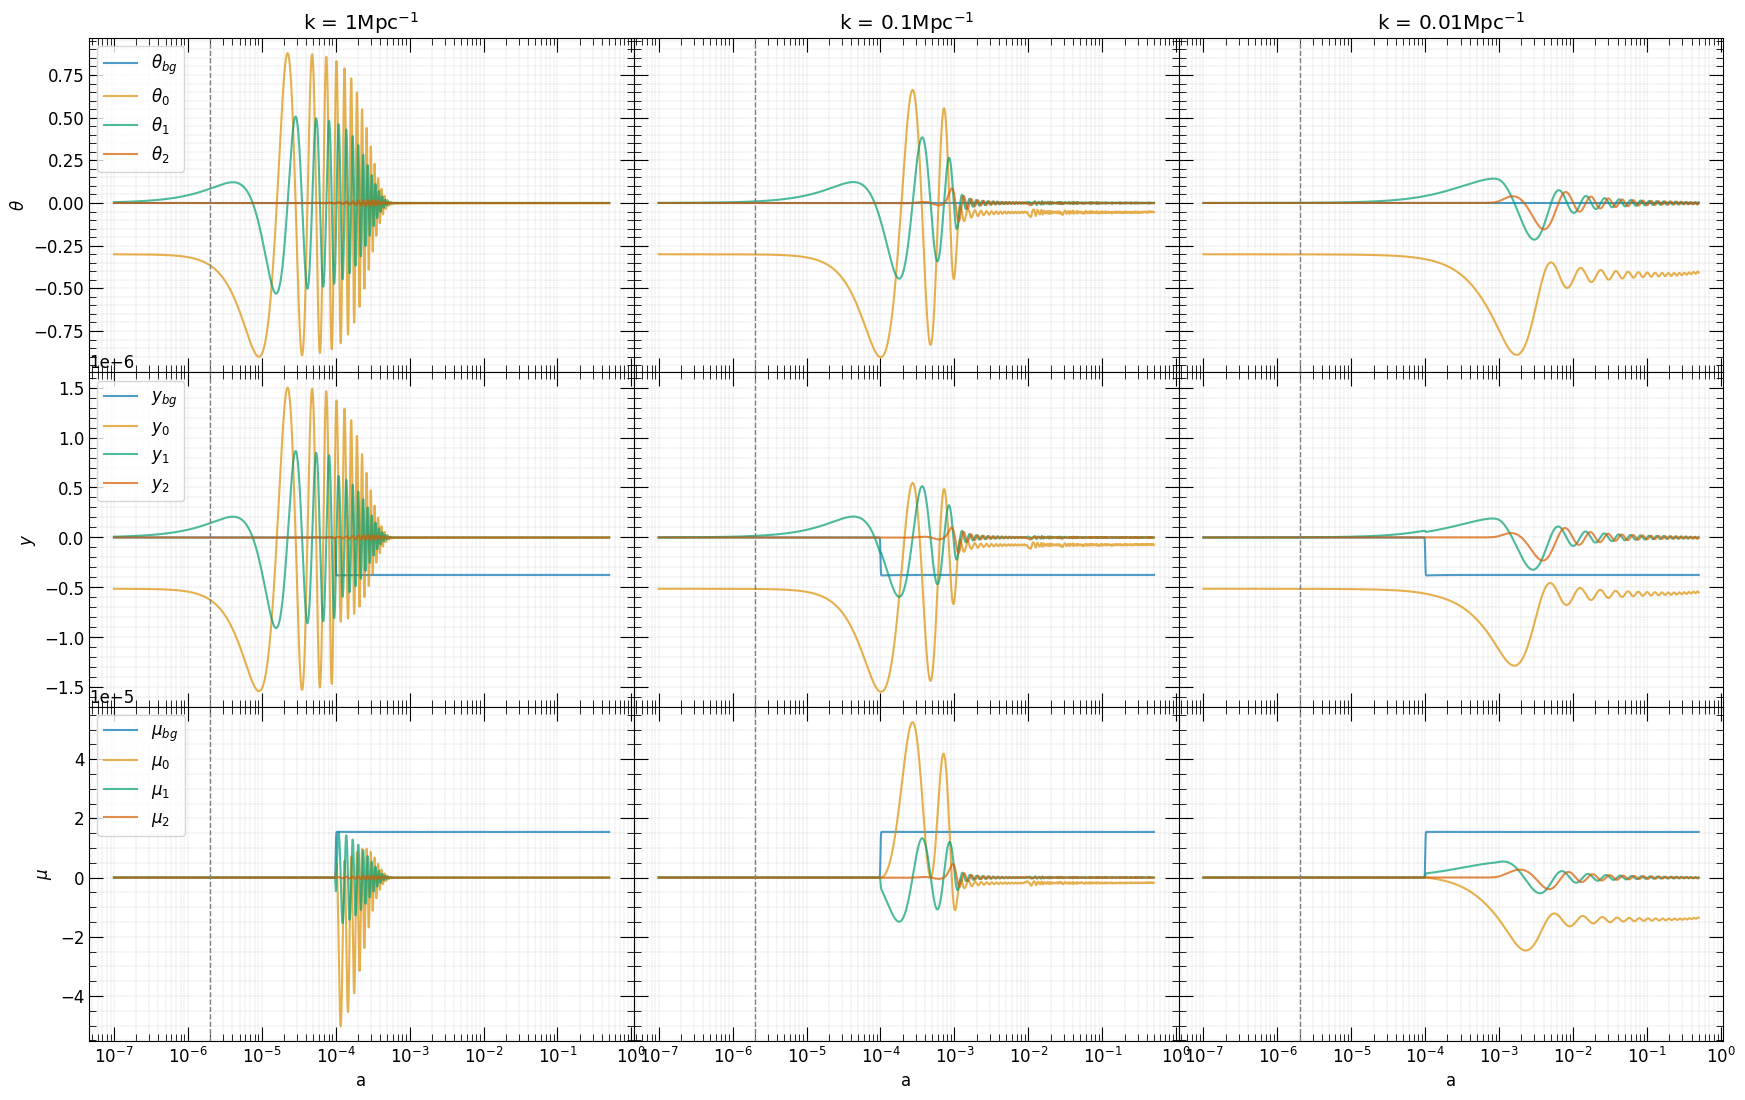

In [ ]:
colors = mplt.set_colors(4, palette="colorblind")

zcon = 5.0e5 # 1.74712e-08 m_dp
# Plot Analytical Spectra
fig, ax1 = plt.subplots(3, 3, figsize=mplt.set_size(mplt.width*3, 1, (3,3)), sharey='row')
fig.subplots_adjust(hspace=0, wspace=0)

# Loop over columns (kv = 001, 002, 003) and rows (ell = 1, 2, 3)
for col in range(len(kv_values_Mpc)):  # columns for different kv values
    ax1[0, col].plot(a[col], theta[col][0], label="$\\theta_{bg}$", color=colors[0], alpha=0.7, linestyle="-")
    ax1[1, col].plot(a[col], y[col][0], label="$y_{bg}$", color=colors[0], alpha=0.7, linestyle="-")
    ax1[2, col].plot(a[col], mu[col][0], label="$\\mu_{bg}$", color=colors[0], alpha=0.7, linestyle="-")
    for ell_idx in range(1, ell+2):  # ell multipoles 1, 2, 3
        ax1[0, col].plot(a[col], theta[col][ell_idx], label=f"$\\theta_{ell_idx-1}$", color=colors[ell_idx], alpha=0.7, linestyle="-")
        ax1[1, col].plot(a[col], y[col][ell_idx], label=f"$y_{ell_idx-1}$", color=colors[ell_idx], alpha=0.7, linestyle="-")
        ax1[2, col].plot(a[col], mu[col][ell_idx], label=f"$\\mu_{ell_idx-1}$", color=colors[ell_idx], alpha=0.7, linestyle="-")
    

    ax1[0, col].set_title(f"k = {kv_values_Mpc[col]}" "${\\rm Mpc^{-1}}$")

# Set labels for left column
ax1[0, 0].set_ylabel("$\\theta$")
ax1[1, 0].set_ylabel("$y$")
ax1[2, 0].set_ylabel("$\\mu$")

# Set x-labels for bottom row only
for col in range(3):
    ax1[2, col].set_xlabel("a")

# Remove x tick labels for top two rows
for row in range(2):
    for col in range(3):
        ax1[row, col].tick_params(labelbottom=False)

# Remove y tick labels for middle and right columns
for row in range(3):
    for col in range(1, 3):
        ax1[row, col].tick_params(labelleft=False)

# Apply formatting to all subplots
for ax in ax1.flat:
    ax.set_xscale('log')
    
    ax.minorticks_on()
    ax.tick_params(direction='in', right=True, top=True)
    ax.tick_params(labelsize=12)
    ax.tick_params(direction='in', which='minor', length=5, bottom=True, top=True, left=True, right=True)
    ax.tick_params(direction='in', which='major', length=10, bottom=True, top=True, left=True, right=True)
    ax.grid(True, which='both', linestyle='--', linewidth=0.3, alpha=0.7)

    ax.axvline(x= 1 / (1+zcon), color='gray', linestyle='dashed', linewidth=1)


# Add legend to first column subplots
ax1[0, 0].legend(loc='upper left')
ax1[1, 0].legend(loc='upper left')
ax1[2, 0].legend(loc='upper left')

#plt.savefig('outputs/H0_evolution.pdf', dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
theta_1 = []
y_1 = []
mu_1 = []
a_1 = []

for kv in kv_values:
    zt, th, yy, m = extract_state_scattering_basis("../Data/dp-aniso-nah1.1/", ell, kv )
    
    theta_1.append(th)
    y_1.append(yy)
    mu_1.append(m)
    a_1.append(zt)

In [ ]:

zcon = 5.0e4 # 1.74712e-08 m_dp
# Plot Analytical Spectra
fig, ax1 = plt.subplots(3, 3, figsize=mplt.set_size(mplt.width*3, 1, (3,3)), sharey='row')
fig.subplots_adjust(hspace=0, wspace=0)

# Loop over columns (kv = 001, 002, 003) and rows (ell = 1, 2, 3)
for col in range(len(kv_values_Mpc)):  # columns for different kv values
    ax1[0, col].plot(a_1[col], theta_1[col][0], label="$\\theta_{bg}$", color=colors[0], alpha=0.7, linestyle="-")
    ax1[1, col].plot(a_1[col], y_1[col][0], label="$y_{bg}$", color=colors[0], alpha=0.7, linestyle="-")
    ax1[2, col].plot(a_1[col], mu_1[col][0], label="$\\mu_{bg}$", color=colors[0], alpha=0.7, linestyle="-")
    for ell_idx in range(1, ell+2):  # ell multipoles 1, 2, 3
        ax1[0, col].plot(a_1[col], theta_1[col][ell_idx], label=f"$\\theta_{ell_idx-1}$", color=colors[ell_idx], alpha=0.7, linestyle="-")
        ax1[1, col].plot(a_1[col], y_1[col][ell_idx], label=f"$y_{ell_idx-1}$", color=colors[ell_idx], alpha=0.7, linestyle="-")
        ax1[2, col].plot(a_1[col], mu_1[col][ell_idx], label=f"$\\mu_{ell_idx-1}$", color=colors[ell_idx], alpha=0.7, linestyle="-")
    

    ax1[0, col].set_title(f"k = {kv_values_Mpc[col]}" "${\\rm Mpc^{-1}}$")

# Set labels for left column
ax1[0, 0].set_ylabel("$\\theta$")
ax1[1, 0].set_ylabel("$y$")
ax1[2, 0].set_ylabel("$\\mu$")

# Set x-labels for bottom row only
for col in range(3):
    ax1[2, col].set_xlabel("a")

# Remove x tick labels for top two rows
for row in range(2):
    for col in range(3):
        ax1[row, col].tick_params(labelbottom=False)

# Remove y tick labels for middle and right columns
for row in range(3):
    for col in range(1, 3):
        ax1[row, col].tick_params(labelleft=False)

# Apply formatting to all subplots
for ax in ax1.flat:
    ax.set_xscale('log')
    
    ax.minorticks_on()
    ax.tick_params(direction='in', right=True, top=True)
    ax.tick_params(labelsize=12)
    ax.tick_params(direction='in', which='minor', length=5, bottom=True, top=True, left=True, right=True)
    ax.tick_params(direction='in', which='major', length=10, bottom=True, top=True, left=True, right=True)
    ax.grid(True, which='both', linestyle='--', linewidth=0.3, alpha=0.7)

    ax.axvline(x= 1 / (1+zcon), color='gray', linestyle='dashed', linewidth=1)


# Add legend to first column subplots
ax1[0, 0].legend(loc='upper left')
ax1[1, 0].legend(loc='upper left')
ax1[2, 0].legend(loc='upper left')

#plt.savefig('outputs/H0_evolution.pdf', dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
theta_2 = []
y_2 = []
mu_2 = []
a_2 = []

for kv in kv_values:
    zt, th, yy, m = extract_state_scattering_basis("../Data/dp-aniso-nah1.2/", ell, kv )
    
    theta_2.append(th)
    y_2.append(yy)
    mu_2.append(m)
    a_2.append(zt)

In [ ]:
zcon = 5.0e4 # 1.74712e-08 m_dp
# Plot Analytical Spectra
fig, ax1 = plt.subplots(3, 3, figsize=mplt.set_size(mplt.width*3, 1, (3,3)), sharey='row')
fig.subplots_adjust(hspace=0, wspace=0)

# Loop over columns (kv = 001, 002, 003) and rows (ell = 1, 2, 3)
for col in range(len(kv_values_Mpc)):  # columns for different kv values
    ax1[0, col].plot(a_2[col], theta_2[col][0], label="$\\theta_{bg}$", color=colors[0], alpha=0.7, linestyle="-")
    ax1[1, col].plot(a_2[col], y_2[col][0], label="$y_{bg}$", color=colors[0], alpha=0.7, linestyle="-")
    ax1[2, col].plot(a_2[col], mu_2[col][0], label="$\\mu_{bg}$", color=colors[0], alpha=0.7, linestyle="-")
    for ell_idx in range(1, ell+2):  # ell multipoles 1, 2, 3
        ax1[0, col].plot(a_2[col], theta_2[col][ell_idx], label=f"$\\theta_{ell_idx-1}$", color=colors[ell_idx], alpha=0.7, linestyle="-")
        ax1[1, col].plot(a_2[col], y_2[col][ell_idx], label=f"$y_{ell_idx-1}$", color=colors[ell_idx], alpha=0.7, linestyle="-")
        ax1[2, col].plot(a_2[col], mu_2[col][ell_idx], label=f"$\\mu_{ell_idx-1}$", color=colors[ell_idx], alpha=0.7, linestyle="-")
    

    ax1[0, col].set_title(f"k = {kv_values_Mpc[col]}" "${\\rm Mpc^{-1}}$")

# Set labels for left column
ax1[0, 0].set_ylabel("$\\theta$")
ax1[1, 0].set_ylabel("$y$")
ax1[2, 0].set_ylabel("$\\mu$")

# Set x-labels for bottom row only
for col in range(3):
    ax1[2, col].set_xlabel("a")

# Remove x tick labels for top two rows
for row in range(2):
    for col in range(3):
        ax1[row, col].tick_params(labelbottom=False)

# Remove y tick labels for middle and right columns
for row in range(3):
    for col in range(1, 3):
        ax1[row, col].tick_params(labelleft=False)

# Apply formatting to all subplots
for ax in ax1.flat:
    ax.set_xscale('log')
    
    ax.minorticks_on()
    ax.tick_params(direction='in', right=True, top=True)
    ax.tick_params(labelsize=12)
    ax.tick_params(direction='in', which='minor', length=5, bottom=True, top=True, left=True, right=True)
    ax.tick_params(direction='in', which='major', length=10, bottom=True, top=True, left=True, right=True)
    ax.grid(True, which='both', linestyle='--', linewidth=0.3, alpha=0.7)

    ax.axvline(x= 1 / (1+zcon), color='gray', linestyle='dashed', linewidth=1)


# Add legend to first column subplots
ax1[0, 0].legend(loc='upper left')
ax1[1, 0].legend(loc='upper left')
ax1[2, 0].legend(loc='upper left')

#plt.savefig('outputs/H0_evolution.pdf', dpi=300, bbox_inches="tight")
plt.show()